In [41]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np

In [53]:
plt.style.use('dark_background')

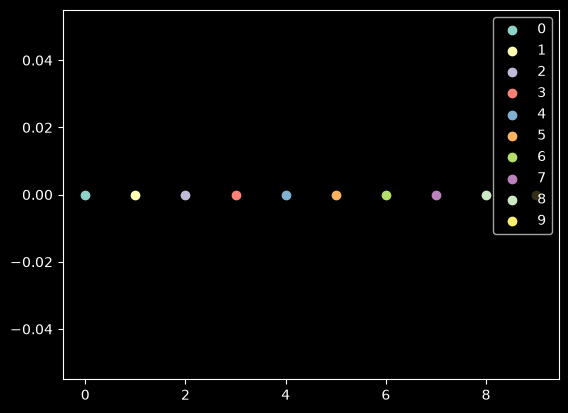

In [84]:
for i in range(10):
    plt.scatter([i], [0], color=f"C{i}", label=f"{i}")
    plt.legend()

In [43]:
Path('plots/edeps').mkdir(parents=True, exist_ok=True)

In [95]:
def A(*a, **kw) -> np.ndarray:
    return np.array(a, **kw)

# from multi_tile_layout-3.0.40_fsdcube.yaml
PITCH = 0.372
TILE_CENTER = A(48.0675, 133.92, 23.808)
TILE_X0, TILE_Y0, TILE_Z0 = TILE_CENTER

COORDS = [('z', 'y'),  # 1st panel
          ('x', 'y'),  # 2nd
          ('x', 'z')]  # 3rd

# XTICKS = np.arange(TILE_X0 - PITCH, TILE_X0 + 5*PITCH, PITCH)
# YTICKS = np.arange(TILE_Y0 - 2*PITCH, TILE_Y0 + 2*PITCH, PITCH)
# ZTICKS = np.arange(TILE_Z0 - 11, TILE_Z0 + 1, 1)

XTICKS = np.linspace(TILE_X0 - 11, TILE_X0 + 1, 13)
YTICKS = np.linspace(TILE_Y0 - 2*PITCH, TILE_Y0 + 2*PITCH, 5)
ZTICKS = np.linspace(TILE_Z0 - PITCH, TILE_Z0 + 5*PITCH, 7)


# LIMITS = [(37, 49),     # x
#           (133, 135),   # y
#           (23, 26)]     # z
LIMITS = [(XTICKS[0], XTICKS[-1]),
          (YTICKS[0], YTICKS[-1]),
          (ZTICKS[0], ZTICKS[-1])]

INPUT_DIR = 'data/edep-sim'

def limits_for(coord_name):
    icoord = ['x', 'y', 'z'].index(coord_name)
    return LIMITS[icoord]

def ticks_for(coord_name):
    icoord = ['x', 'y', 'z'].index(coord_name)
    return [XTICKS, YTICKS, ZTICKS][icoord]

def draw_pixel(i_panel, ax, color='C3'):
    if i_panel == 0:
        ll_corner = (TILE_Z0, TILE_Y0)
        pixel = Rectangle(ll_corner, PITCH, PITCH,
                          facecolor='none', edgecolor=color, linewidth=2)
        ax.add_patch(pixel)
        ax.axvline(TILE_Z0 + 3.5*PITCH)
    else:
        p0 = TILE_CENTER[i_panel]
        pixel = Line2D([TILE_X0, TILE_X0], [p0, p0 + PITCH],
                       color=color)
        ax.add_line(pixel)

def plot_edeps(name):
    with h5py.File(f'{INPUT_DIR}/{name}.hdf5') as f:
        segs = f['segments'][:]
        global SEGS
        SEGS = segs
    fig, axs = plt.subplots(1, 3, figsize=(20, 5))
    for i, ax in enumerate(axs):
        a, b = COORDS[i]
        u, u1, u2 = segs[a], segs[f'{a}_start'], segs[f'{a}_end']
        v, v1, v2 = segs[b], segs[f'{b}_start'], segs[f'{b}_end']
        line_segs = np.stack([np.column_stack([u1, v1]),
                              np.column_stack([u2, v2])],
                             axis=1)
        lc = LineCollection(line_segs)
        ax.add_collection(lc)
        ax.scatter(u, v, color='C0', s=24)
        draw_pixel(i, ax)
        ax.set_xlim(limits_for(a))
        ax.set_ylim(limits_for(b))
        ax.set_aspect('equal', adjustable='box')
        ax.set_xticks(ticks_for(a))
        ax.set_yticks(ticks_for(b))
        ax.grid(True, linestyle='--')
        ax.set_xlabel(f'{a} [cm]')
        ax.set_ylabel(f'{b} [cm]')
    fig.suptitle(name)
    fig.savefig(f'plots/edeps/{name}.png')

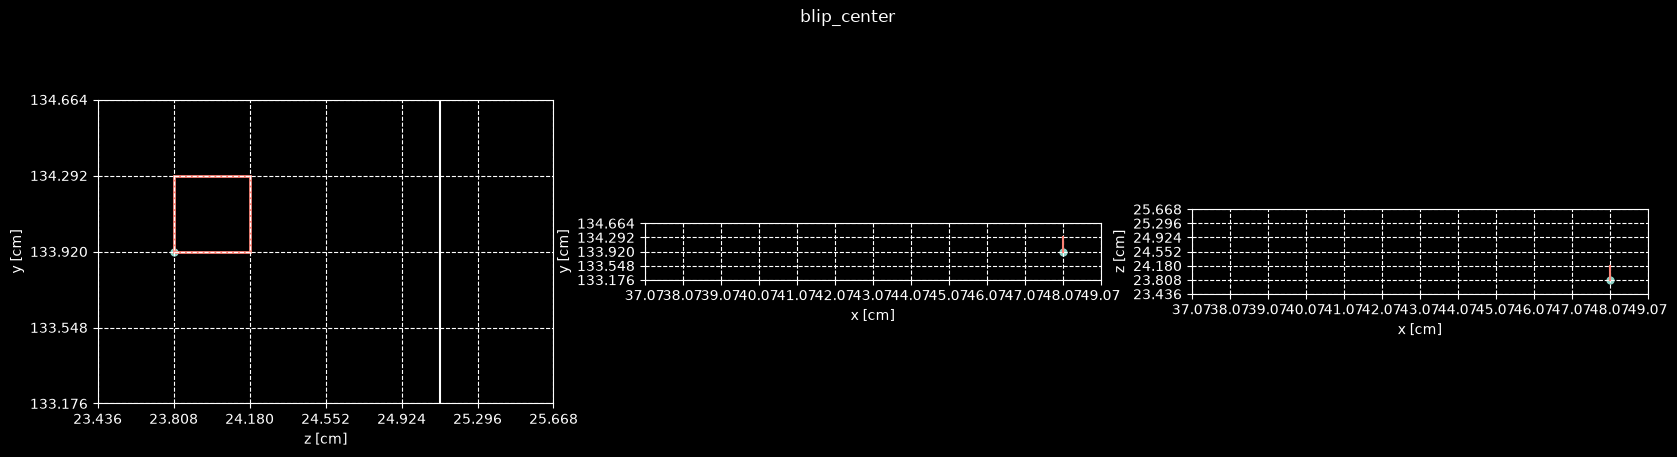

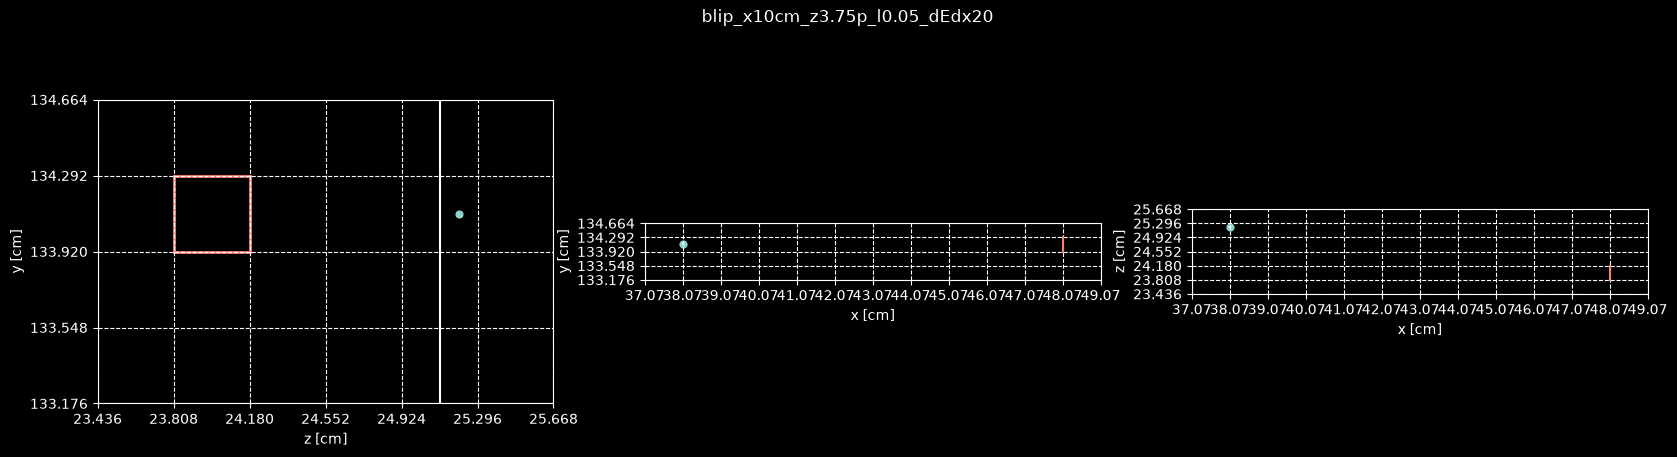

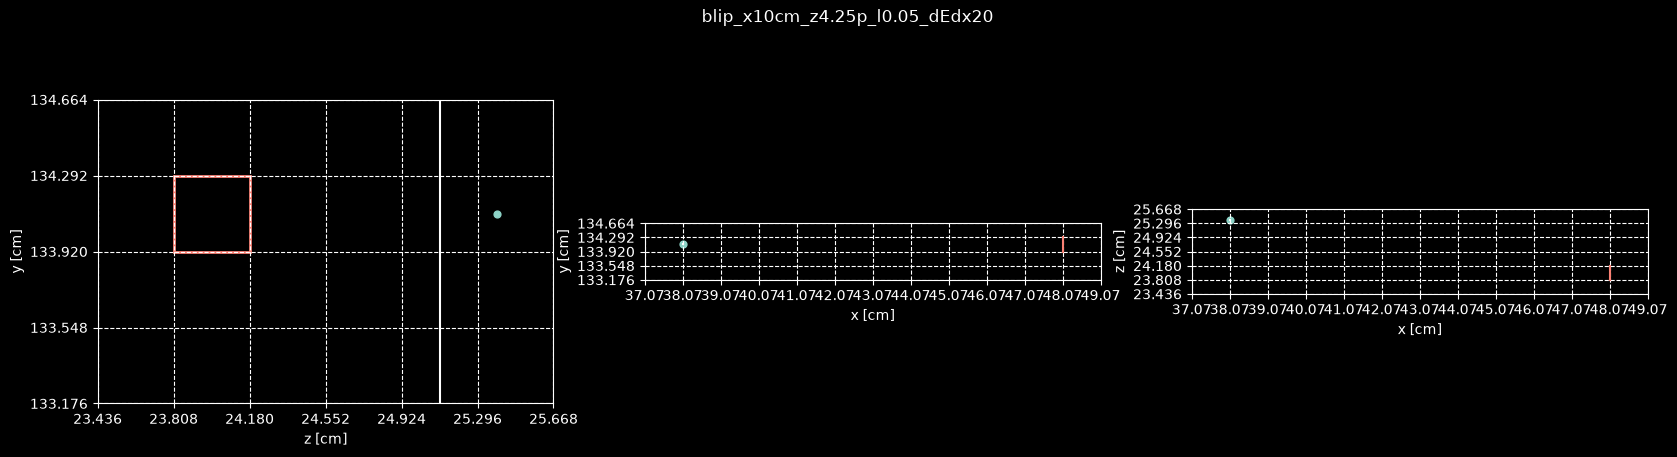

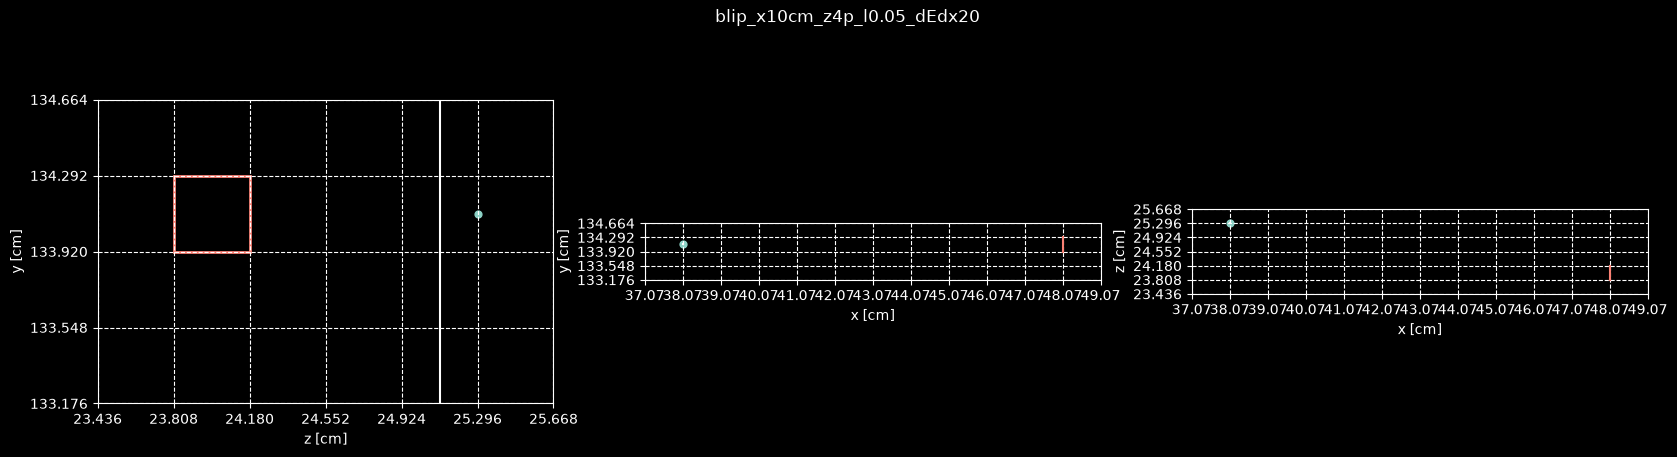

In [101]:
for h5f in sorted(Path(INPUT_DIR).glob('*.hdf5')):
    plot_edeps(h5f.stem)